# Undiagnosed diabetes in US adults

**How many adults have diabetes without knowing it, who are they, and which screening rule finds them?**

Data: NHANES August 2021 to August 2023 (US National Center for Health Statistics). NHANES examines a
sample of the population and takes blood, so it can find diabetes in people who have never been told
they have it.

Definitions used throughout:

- **Diagnosed diabetes**: answered yes to "has a doctor ever told you that you have diabetes?"
- **Undiagnosed diabetes**: no such diagnosis, and HbA1c of 6.5% or higher in the survey's blood test.
- **Prediabetes range**: no diagnosis, HbA1c from 5.7% to 6.4%.

This notebook is generated from `analysis.py` by `scripts/build_notebook.py`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "survey.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import charts  # noqa: E402
from survey import Design, dummies  # noqa: E402

RESULTS, FIGURES = ROOT / "results", ROOT / "figures"
pd.set_option("display.width", 160, "display.max_columns", 20, "display.float_format", "{:,.2f}".format)

data = pd.read_csv(ROOT / "data" / "analysis" / "nhanes_participants.csv")
data["insurance"] = data.insured.map({1.0: "Insured", 0.0: "Uninsured"})
data["usual_care"] = data.usual_place_of_care.map({1.0: "Has a usual place of care", 0.0: "No usual place of care"})

# The blood-test weight, with the survey's strata and sampling units.
design = Design(data, weight="lab_weight", stratum="stratum", psu="psu")
adults = data.in_analysis == 1
print(f"{len(data):,} participants; {design.n_strata} strata, {design.n_psu} sampling units, "
      f"{design.df} degrees of freedom; t multiplier {design.t:.3f}")

11,933 participants; 15 strata, 30 sampling units, 15 degrees of freedom; t multiplier 2.131


## 1. Who is in the analysis

Adults aged 20 or over who were not pregnant, gave blood, have an HbA1c result and answered the
diabetes question. People outside this group stay in the data with a flag: the variance formula
needs every sampling unit, so nobody is deleted.

In [2]:
display(pd.read_csv(RESULTS / "sample_flow.csv"))

,step,participants
0,All participants,11933
1,Aged 20 or over,7809
2,Not pregnant,7768
3,Gave a blood sample (lab weight above zero),5755
4,HbA1c result available,5730
5,Answered the diabetes question,5730


## 2. How common is it?

Percentages are weighted to the US adult population. Intervals are 95% and account for the survey design.

In [3]:
def percent(result: dict) -> dict:
    """An estimate and its interval, as percentages."""
    return {"estimate": 100 * result["estimate"], "low": 100 * result["low"], "high": 100 * result["high"], "n": result["n"]}


STATUSES = ["Normal range", "Prediabetes range", "Undiagnosed diabetes", "Diagnosed diabetes"]
status_rows = []
for status in STATUSES:
    indicator = (data.status == status).astype(float).where(data.status.notna())
    people = design.total(indicator, adults)
    status_rows.append({"status": status, **percent(design.proportion(indicator, adults)),
                        "million_adults": people["estimate"] / 1e6,
                        "million_low": people["low"] / 1e6, "million_high": people["high"] / 1e6})
status_table = pd.DataFrame(status_rows)
status_table.to_csv(RESULTS / "glycaemic_status.csv", index=False)
display(status_table)

with_diabetes = adults & (data.has_diabetes == 1)
unaware = percent(design.proportion(data.undiagnosed, with_diabetes))
print(f"Of adults with diabetes, {unaware['estimate']:.1f}% ({unaware['low']:.1f} to {unaware['high']:.1f}) are undiagnosed "
      f"(n = {unaware['n']:,} with diabetes).")

,status,estimate,low,high,n,million_adults,million_low,million_high
0,Normal range,64.19,61.00,67.25,5730,155.35,131.72,178.98
1,Prediabetes range,21.77,19.73,23.97,5730,52.70,46.67,58.72
2,Undiagnosed diabetes,2.28,1.82,2.85,5730,5.52,4.11,6.92
3,Diagnosed diabetes,11.76,10.32,13.36,5730,28.45,25.34,31.57


Of adults with diabetes, 16.2% (13.0 to 20.1) are undiagnosed (n = 971 with diabetes).


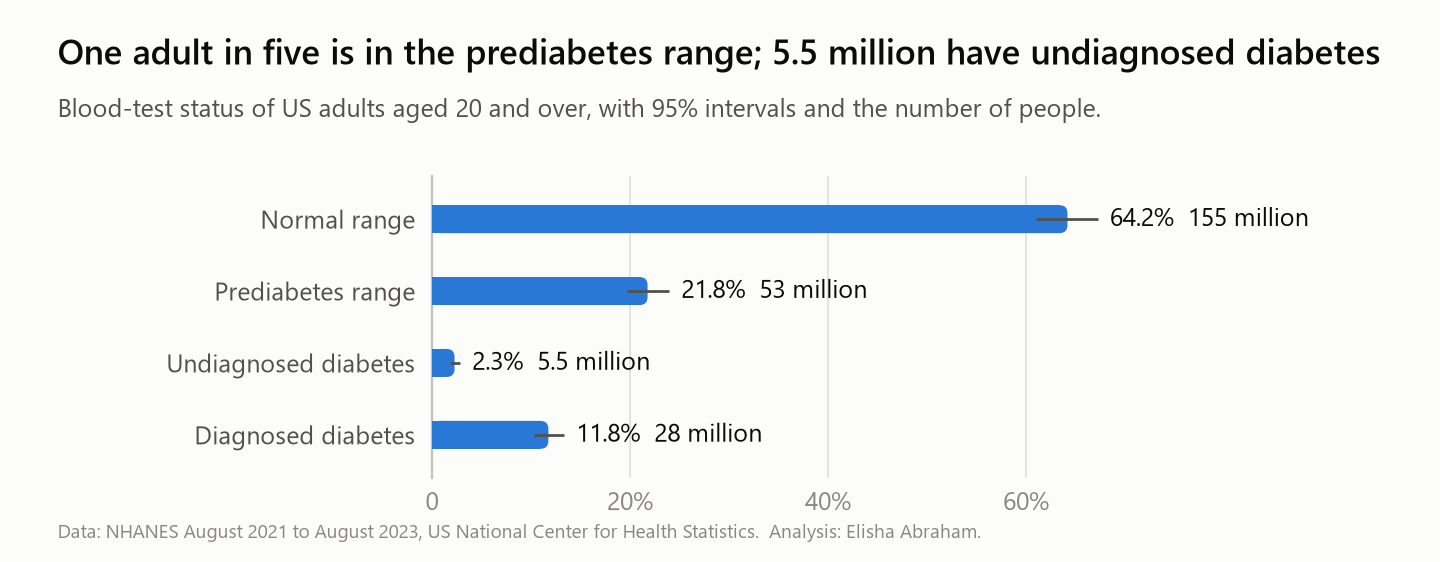

In [4]:
path = charts.interval_bars(
    [{"label": row.status, "estimate": row.estimate, "low": row.low, "high": row.high,
      "note": f"{row.million_adults:.0f} million" if row.million_adults >= 9.5 else f"{row.million_adults:.1f} million"}
     for row in status_table.itertuples()],
    "One adult in five is in the prediabetes range; 5.5 million have undiagnosed diabetes",
    "Blood-test status of US adults aged 20 and over, with 95% intervals and the number of people.",
    FIGURES, "glycaemic_status", x_max=96, ticks=[0, 20, 40, 60], label_width=0.30)
display(Image(str(path), width=720))

## 3. Among people with diabetes, who does not know?

The share of diabetes that is undiagnosed, by group. Groups with fewer than 30 people with diabetes
in the sample are not reported.

In [5]:
GROUPS = {
    "Age": ("age_group", ["20-39", "40-59", "60 and over"]),
    "Sex": ("sex", ["Female", "Male"]),
    "Race and ethnicity": ("race_ethnicity", ["Non-Hispanic White", "Non-Hispanic Black", "Hispanic", "Non-Hispanic Asian", "Other or multiracial"]),
    "Health insurance": ("insurance", ["Insured", "Uninsured"]),
    "Usual place of care": ("usual_care", ["Has a usual place of care", "No usual place of care"]),
}
share_rows = [{"group": "All adults with diabetes", "level": "All", **unaware}]
for group, (variable, levels) in GROUPS.items():
    for level in levels:
        share_rows.append({"group": group, "level": level,
                           **percent(design.proportion(data.undiagnosed, with_diabetes & (data[variable] == level)))})
share_table = pd.DataFrame(share_rows)
share_table["reported"] = share_table.n >= 30
share_table.to_csv(RESULTS / "undiagnosed_share_by_group.csv", index=False)
display(share_table)

,group,level,estimate,low,high,n,reported
0,All adults with diabetes,All,16.24,13.03,20.05,971,True
1,Age,20-39,22.93,13.21,36.77,52,True
2,Age,40-59,17.70,13.27,23.22,277,True
3,Age,60 and over,14.15,11.04,17.96,642,True
4,Sex,Female,14.98,14.07,15.93,493,True
5,Sex,Male,17.38,11.81,24.83,478,True
6,Race and ethnicity,Non-Hispanic White,15.21,10.70,21.16,497,True
7,Race and ethnicity,Non-Hispanic Black,17.53,10.54,27.71,164,True
8,Race and ethnicity,Hispanic,19.77,14.99,25.60,189,True
9,Race and ethnicity,Non-Hispanic Asian,26.58,14.75,43.10,50,True


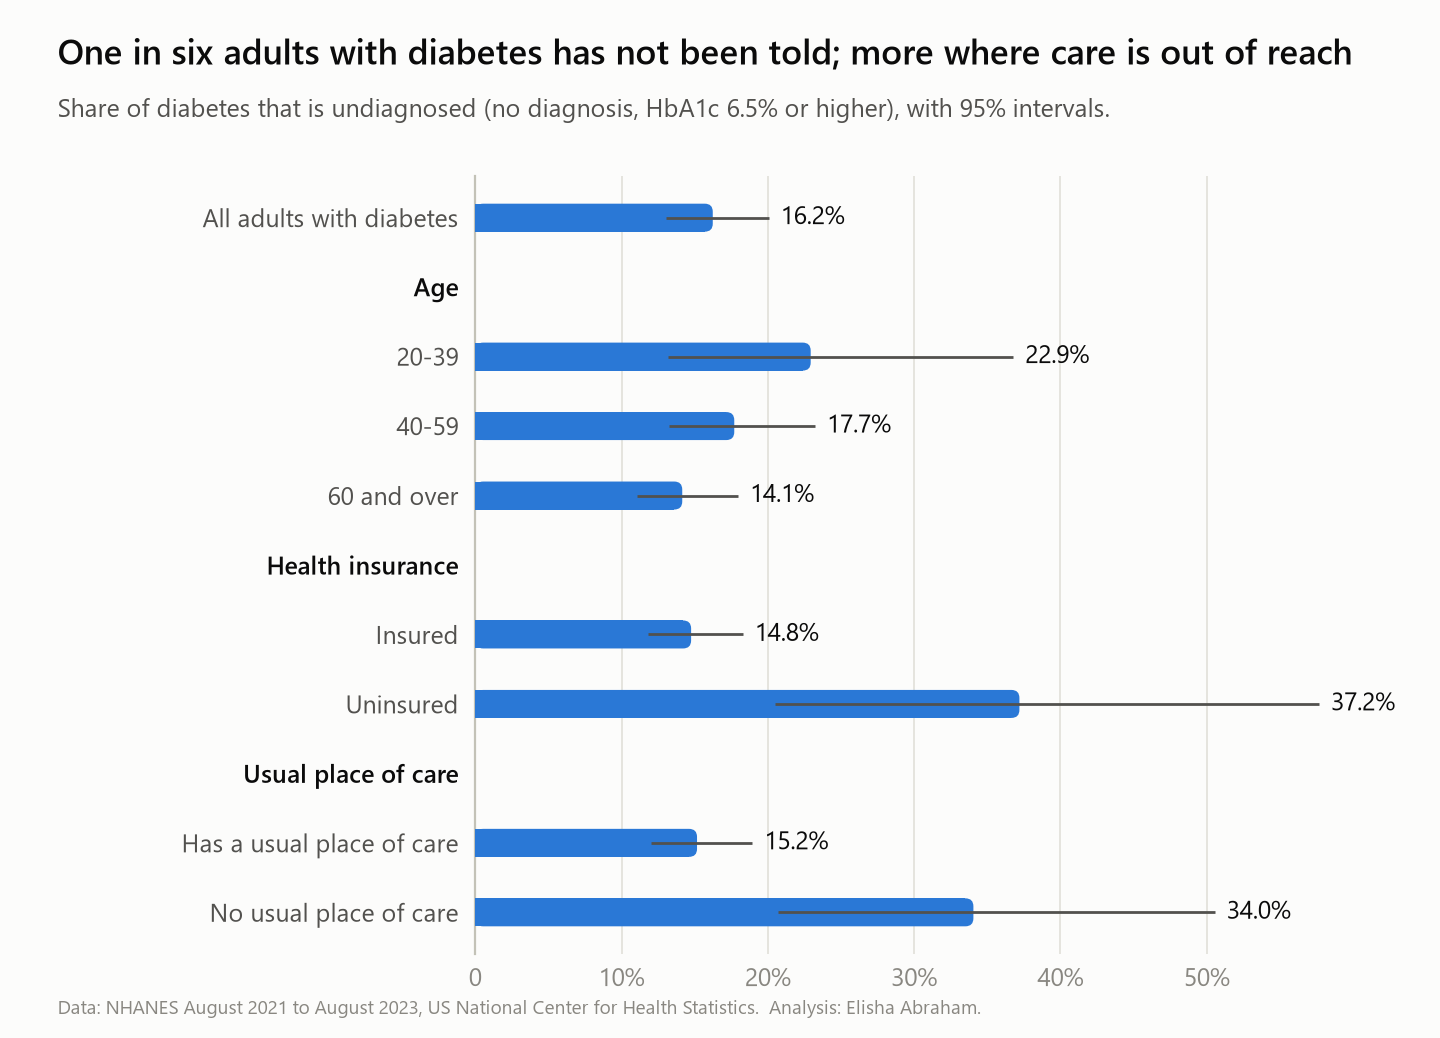

In [6]:
chart_rows = [{"label": "All adults with diabetes", **unaware, "note": ""}]
for group in ["Age", "Health insurance", "Usual place of care"]:
    chart_rows.append({"label": group, "estimate": None})
    for row in share_table[(share_table.group == group) & share_table.reported].itertuples():
        chart_rows.append({"label": row.level, "estimate": row.estimate, "low": row.low, "high": row.high})
path = charts.interval_bars(
    chart_rows,
    "One in six adults with diabetes has not been told; more where care is out of reach",
    "Share of diabetes that is undiagnosed (no diagnosis, HbA1c 6.5% or higher), with 95% intervals.",
    FIGURES, "undiagnosed_share_by_group", x_max=62, ticks=[0, 10, 20, 30, 40, 50])
display(Image(str(path), width=720))

## 4. Among adults with no diagnosis, what predicts an HbA1c of 6.5% or higher?

A logistic regression, weighted, with standard errors from the survey design. With 15 degrees of
freedom the model has to stay small: five predictors, ten coefficients.

In [7]:
no_diagnosis = adults & (data.diagnosed == 0)
LEVELS = {
    "age_group": ["20-39", "40-59", "60 and over"],
    "sex": ["Female", "Male"],
    "race_ethnicity": ["Non-Hispanic White", "Non-Hispanic Black", "Hispanic", "Non-Hispanic Asian", "Other or multiracial"],
    "bmi_group": ["Under 25", "25 to 29.9", "30 and over"],
    "insurance": ["Insured", "Uninsured"],
}
X = dummies(data, LEVELS)
model = design.logistic(X, data.undiagnosed, no_diagnosis)
model.to_csv(RESULTS / "model_odds_ratios.csv", index=False)
display(model[["term", "odds_ratio", "low", "high", "p_value"]])
print(f"n = {model.n.iloc[0]:,} adults without a diagnosis; {model.events.iloc[0]:,} with HbA1c of 6.5% or higher")

# Crude (unadjusted) prevalence of undiagnosed diabetes in the same groups, for context.
crude_rows = []
for variable, levels in LEVELS.items():
    for level in levels:
        crude_rows.append({"variable": variable, "level": level,
                           **percent(design.proportion(data.undiagnosed, no_diagnosis & (data[variable] == level)))})
crude = pd.DataFrame(crude_rows)
crude.to_csv(RESULTS / "undiagnosed_prevalence_by_group.csv", index=False)
display(crude)

,term,odds_ratio,low,high,p_value
0,Intercept,0.00,0.00,0.00,0.00
1,age_group: 40-59,3.62,2.34,5.59,0.00
2,age_group: 60 and over,7.31,4.77,11.21,0.00
3,sex: Male,1.45,0.79,2.64,0.21
4,race_ethnicity: Non-Hispanic Black,2.31,1.33,4.02,0.01
5,race_ethnicity: Hispanic,1.75,0.82,3.72,0.14
6,race_ethnicity: Non-Hispanic Asian,4.37,1.90,10.07,0.00
7,race_ethnicity: Other or multiracial,0.53,0.14,1.97,0.32
8,bmi_group: 25 to 29.9,2.29,1.24,4.23,0.01
9,bmi_group: 30 and over,10.95,5.09,23.55,0.00


n = 4,843 adults without a diagnosis; 149 with HbA1c of 6.5% or higher


,variable,level,estimate,low,high,n
0,age_group,20-39,0.84,0.53,1.33,1376
1,age_group,40-59,3.11,2.19,4.39,1439
2,age_group,60 and over,4.34,3.47,5.41,2096
3,sex,Female,2.20,1.73,2.79,2727
4,sex,Male,2.99,1.98,4.48,2184
5,race_ethnicity,Non-Hispanic White,2.11,1.42,3.14,2985
6,race_ethnicity,Non-Hispanic Black,4.72,2.88,7.63,541
7,race_ethnicity,Hispanic,3.25,2.07,5.07,812
8,race_ethnicity,Non-Hispanic Asian,3.38,1.95,5.79,277
9,race_ethnicity,Other or multiracial,0.97,0.32,2.86,296


**Check.** The coefficients are fitted here with Newton's method. statsmodels, fitting the same
weighted model, must give the same coefficients.

In [8]:
import statsmodels.api as sm  # noqa: E402

rows = no_diagnosis & X.notna().all(axis=1) & data.undiagnosed.notna()
reference = sm.GLM(data.undiagnosed[rows], X[rows], family=sm.families.Binomial(),
                   freq_weights=data.lab_weight[rows] / data.lab_weight[rows].mean()).fit()
largest_gap = float(np.abs(reference.params.to_numpy() - model.coefficient.to_numpy()).max())
assert largest_gap < 1e-6, largest_gap
print(f"Largest difference from statsmodels across {len(model)} coefficients: {largest_gap:.1e}")

Largest difference from statsmodels across 11 coefficients: 3.4e-12


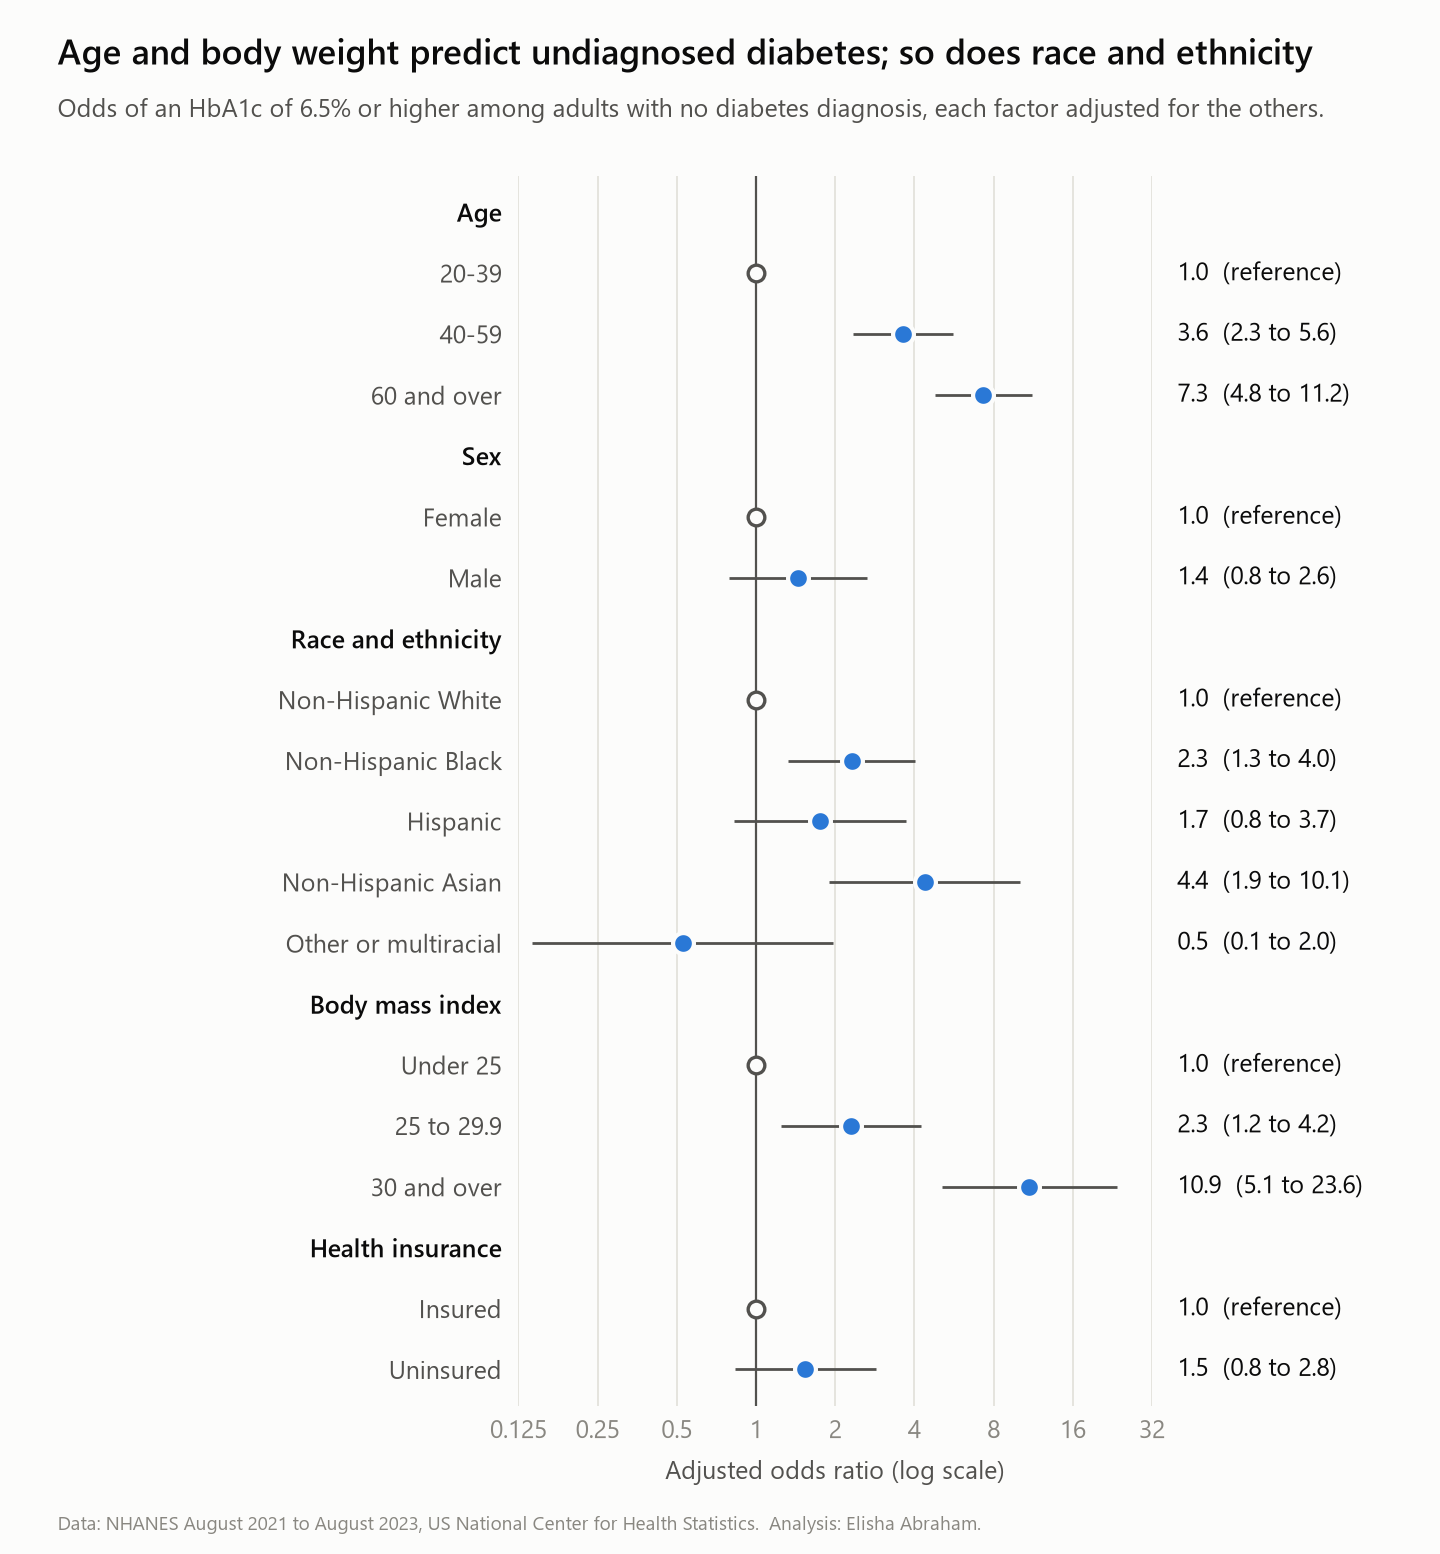

In [9]:
LABELS = {"age_group": "Age", "sex": "Sex", "race_ethnicity": "Race and ethnicity", "bmi_group": "Body mass index", "insurance": "Health insurance"}
by_term = model.set_index("term")
forest_rows = []
for variable, levels in LEVELS.items():
    forest_rows.append({"label": LABELS[variable]})
    forest_rows.append({"label": levels[0], "reference": True})
    for level in levels[1:]:
        row = by_term.loc[f"{variable}: {level}"]
        forest_rows.append({"label": level, "odds_ratio": row.odds_ratio, "low": row.low, "high": row.high})
path = charts.forest(
    forest_rows,
    "Age and body weight predict undiagnosed diabetes; so does race and ethnicity",
    "Odds of an HbA1c of 6.5% or higher among adults with no diabetes diagnosis, each factor adjusted for the others.",
    FIGURES, "odds_ratios", x_ticks=[0.125, 0.25, 0.5, 1, 2, 4, 8, 16, 32])
display(Image(str(path), width=720))

## 5. Are the undiagnosed in contact with the health system?

In [10]:
undiagnosed = adults & (data.undiagnosed == 1)
contact_rows = []
for label, column in [("Has health insurance", "insured"), ("Has a usual place of care", "usual_place_of_care"),
                      ("Has been told they have high blood pressure", "told_high_blood_pressure"),
                      ("Has been told they have prediabetes", "told_prediabetes")]:
    contact_rows.append({"among adults with undiagnosed diabetes": label, **percent(design.proportion(data[column], undiagnosed))})
contact = pd.DataFrame(contact_rows)
contact.to_csv(RESULTS / "contact_with_care.csv", index=False)
display(contact)

# The same question one step earlier: of adults in the prediabetes range, how many have been told?
in_prediabetes_range = adults & (data.status == "Prediabetes range")
told = percent(design.proportion(data.told_prediabetes, in_prediabetes_range))
pd.DataFrame([{"among adults in the prediabetes range": "Has been told they have prediabetes", **told}]).to_csv(
    RESULTS / "prediabetes_awareness.csv", index=False)
print(f"Of adults in the prediabetes range, {told['estimate']:.1f}% ({told['low']:.1f} to {told['high']:.1f}) "
      f"have been told they have prediabetes (n = {told['n']:,}).")

,among adults with undiagnosed diabetes,estimate,low,high,n
0,Has health insurance,85.58,75.86,91.80,151
1,Has a usual place of care,88.06,77.94,93.90,152
2,Has been told they have high blood pressure,49.72,38.01,61.45,152
3,Has been told they have prediabetes,40.24,31.29,49.89,115


Of adults in the prediabetes range, 27.1% (23.8 to 30.8) have been told they have prediabetes (n = 1,266).


## 6. Which screening rule finds them?

Each rule is applied to adults with no diagnosis. Three questions per rule: how many adults would be
tested, what share of the undiagnosed cases are among them, and how many tests it takes to find one case.

In [11]:
asian = data.race_ethnicity == "Non-Hispanic Asian"
has_bmi = data.bmi.notna()
RULES = {
    "Age 35 to 70 with BMI of 25 or over (USPSTF 2021)": (data.age.between(35, 70) & (data.bmi >= 25)).where(has_bmi),
    "The same, with BMI of 23 or over for Asian adults": (data.age.between(35, 70) & ((data.bmi >= 25) | (asian & (data.bmi >= 23)))).where(has_bmi),
    "Everyone aged 35 or over": (data.age >= 35),
    "Everyone aged 45 or over": (data.age >= 45),
}
rule_rows = []
for name, rule in RULES.items():
    eligible = rule.astype(float)
    tested = percent(design.proportion(eligible, no_diagnosis))
    found = percent(design.proportion(eligible, no_diagnosis & (data.undiagnosed == 1)))
    yield_ = percent(design.proportion(data.undiagnosed, no_diagnosis & (eligible == 1)))
    rule_rows.append({"rule": name, "adults_tested_pct": tested["estimate"],
                      "cases_covered_pct": found["estimate"], "cases_covered_low": found["low"], "cases_covered_high": found["high"],
                      "cases_per_100_tests": yield_["estimate"], "tests_per_case": 100 / yield_["estimate"]})
rules = pd.DataFrame(rule_rows)
rules.to_csv(RESULTS / "screening_rules.csv", index=False)
display(rules)

,rule,adults_tested_pct,cases_covered_pct,cases_covered_low,cases_covered_high,cases_per_100_tests,tests_per_case
0,Age 35 to 70 with BMI of 25 or over (USPSTF 2021),43.63,68.21,58.59,76.49,4.05,24.71
1,"The same, with BMI of 23 or over for Asian adults",44.43,68.81,59.14,77.07,4.01,24.94
2,Everyone aged 35 or over,70.83,94.95,92.17,96.78,3.46,28.89
3,Everyone aged 45 or over,51.74,77.48,69.45,83.89,3.87,25.86


Who does the first rule miss? Each undiagnosed case falls in exactly one of these groups.

In [12]:
cases = no_diagnosis & (data.undiagnosed == 1) & has_bmi
missed_rows = []
for label, group in [
    ("Covered: aged 35 to 70 with BMI of 25 or over", data.age.between(35, 70) & (data.bmi >= 25)),
    ("Missed: older than 70", data.age > 70),
    ("Missed: aged 35 to 70 with BMI under 25", data.age.between(35, 70) & (data.bmi < 25)),
    ("Missed: younger than 35", data.age < 35),
]:
    missed_rows.append({"undiagnosed cases": label, **percent(design.proportion(group.astype(float), cases))})
missed = pd.DataFrame(missed_rows)
missed.to_csv(RESULTS / "who_the_rule_misses.csv", index=False)
display(missed)

,undiagnosed cases,estimate,low,high,n
0,Covered: aged 35 to 70 with BMI of 25 or over,68.21,58.59,76.49,150
1,Missed: older than 70,23.45,16.88,31.61,150
2,Missed: aged 35 to 70 with BMI under 25,3.25,1.47,7.05,150
3,Missed: younger than 35,5.09,3.26,7.87,150


## Limits

- HbA1c alone is used. Surveys that also use fasting glucose find somewhat more undiagnosed diabetes.
- One blood test is not a clinical diagnosis, which needs a repeat test.
- "Diagnosed" is self-reported.
- This cycle has 15 degrees of freedom, so intervals are wide and small groups cannot be reported.
  The standard errors are themselves estimates from 30 sampling units, so an interval can come out
  too narrow or too wide by chance; the interval for women in section 3 is an example of too narrow.
- The data describe the United States in 2021 to 2023.